In [1]:
!pip install -q ultralytics

In [2]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
from google.colab import files
from IPython.display import display

print("=" * 60)
print("       VISIONPORT OBJECT DETECTION SYSTEM")
print("=" * 60)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
       VISIONPORT OBJECT DETECTION SYSTEM


In [4]:
print("\nUpload a real photograph...")
uploaded = files.upload()

image_path = list(uploaded.keys())[0]


Upload a real photograph...


Saving Screenshot 2026-11-23 120839.png to Screenshot 2026-11-23 120839 (1).png


In [5]:
print("\nLoading YOLOv8 pretrained model...")
model = YOLO("yolov8n.pt")

print("Model loaded successfully!")


Loading YOLOv8 pretrained model...
Model loaded successfully!


In [6]:
image = cv2.imread(image_path)

if image is None:
    raise ValueError("Image could not be loaded!")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("\nImage Acquisition Completed")
print("Original Image Size:", image_rgb.shape)


Image Acquisition Completed
Original Image Size: (498, 856, 3)


In [7]:
print("\nPerforming Object Detection...")

results = model.predict(
    source=image_path,
    conf=0.25,
    imgsz=640,
    verbose=False
)


Performing Object Detection...


In [8]:
output_image = results[0].plot()
output_image = cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB)

In [9]:
print("\nOBJECT DETECTION RESULTS")
print("-" * 50)

boxes = results[0].boxes

if boxes is not None and len(boxes) > 0:

    for i, box in enumerate(boxes):
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        object_name = model.names[class_id]

        x1, y1, x2, y2 = map(int, box.xyxy[0])

        print(f"{i+1}. Object: {object_name}")
        print(f"   Confidence: {confidence*100:.2f}%")
        print(f"   Bounding Box: ({x1}, {y1}, {x2}, {y2})")

else:
    print("No objects detected.")


OBJECT DETECTION RESULTS
--------------------------------------------------
1. Object: car
   Confidence: 90.96%
   Bounding Box: (342, 193, 514, 264)
2. Object: car
   Confidence: 86.97%
   Bounding Box: (226, 184, 413, 261)
3. Object: car
   Confidence: 82.58%
   Bounding Box: (126, 249, 245, 341)
4. Object: car
   Confidence: 78.48%
   Bounding Box: (212, 372, 380, 493)
5. Object: person
   Confidence: 73.12%
   Bounding Box: (602, 322, 654, 411)
6. Object: motorcycle
   Confidence: 71.87%
   Bounding Box: (453, 435, 512, 497)
7. Object: person
   Confidence: 71.75%
   Bounding Box: (779, 382, 835, 470)
8. Object: person
   Confidence: 70.41%
   Bounding Box: (449, 390, 503, 485)
9. Object: car
   Confidence: 66.15%
   Bounding Box: (90, 223, 180, 298)
10. Object: person
   Confidence: 65.23%
   Bounding Box: (74, 323, 115, 394)
11. Object: car
   Confidence: 62.67%
   Bounding Box: (169, 193, 246, 249)
12. Object: motorcycle
   Confidence: 60.44%
   Bounding Box: (784, 435, 835, 4

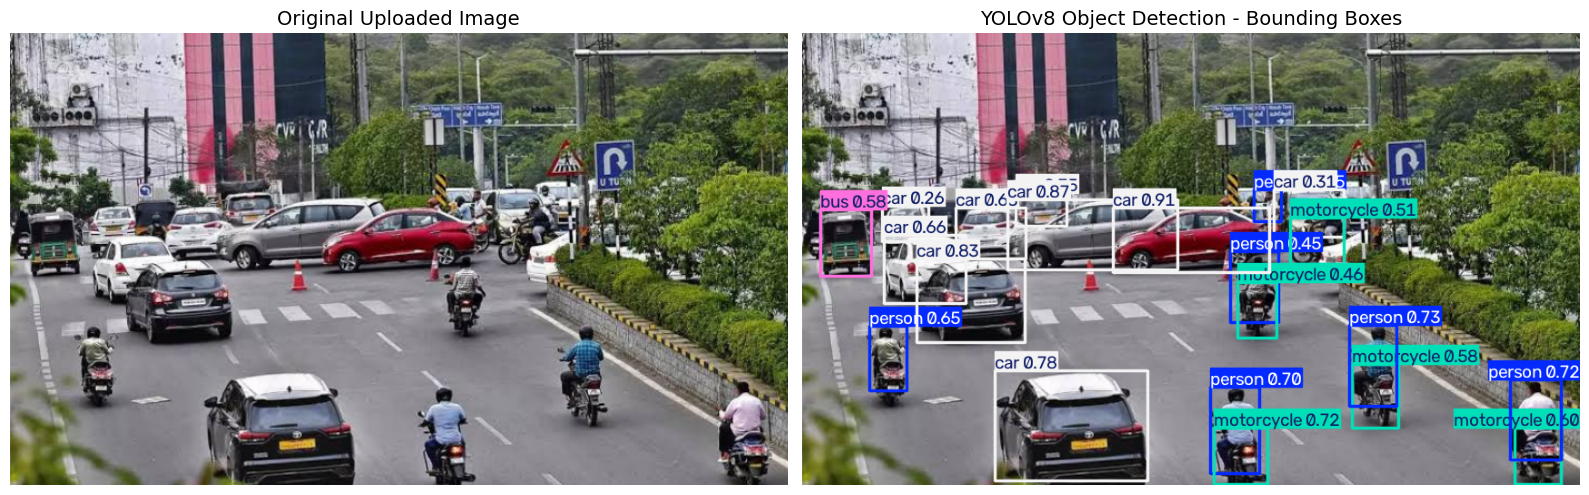

In [10]:
plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Uploaded Image", fontsize=14)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output_image)
plt.title("YOLOv8 Object Detection - Bounding Boxes", fontsize=14)
plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
output_path = "VisionPort_Detection_Output.jpg"

cv2.imwrite(
    output_path,
    cv2.cvtColor(output_image, cv2.COLOR_RGB2BGR)
)

# 11. FINAL SYSTEM REPORT
print("\n" + "=" * 60)
print("           VISIONPORT SYSTEM REPORT")
print("=" * 60)

print("Image Acquisition       : SUCCESS")
print("Image Preprocessing     : SUCCESS")
print("YOLOv8 Model Loading    : SUCCESS")
print("Object Detection        : SUCCESS")
print("Bounding Box Generation: SUCCESS")
print("Output Visualization    : SUCCESS")
print("Total Objects Detected :", len(boxes))
print("=" * 60)
print("VISIONPORT PIPELINE COMPLETED!")


           VISIONPORT SYSTEM REPORT
Image Acquisition       : SUCCESS
Image Preprocessing     : SUCCESS
YOLOv8 Model Loading    : SUCCESS
Object Detection        : SUCCESS
Bounding Box Generation: SUCCESS
Output Visualization    : SUCCESS
Total Objects Detected : 21
VISIONPORT PIPELINE COMPLETED!
